In [1]:
need_install_package = False
if need_install_package:
    !pip install tushare
    !pip install chart-studio
    !pip install xlwt

Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple
Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple
Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple


In [2]:
!pip list

Package                           Version
--------------------------------- ---------------
aiohttp                           3.9.1
aiosignal                         1.3.1
anyio                             4.2.0
argon2-cffi                       21.3.0
argon2-cffi-bindings              21.2.0
arrow                             1.3.0
asttokens                         2.0.5
async-timeout                     4.0.3
attrs                             23.2.0
backcall                          0.2.0
bayesian-optimization             1.4.1
beautifulsoup4                    4.12.3
bleach                            4.1.0
bs4                               0.0.2
cachetools                        5.3.2
certifi                           2022.6.15
cffi                              1.15.0
charset-normalizer                3.3.2
chart-studio                      1.1.0
click                             8.1.7
cloudpickle                       3.0.0
colorama                          0.4.5
comm               

## 读取数据

In [3]:
# 设置Tushare token
# ts.set_token('xxx')  # 替换为你的Tushare Token
# pro = ts.pro_api()
# stock_list = ['002847.SZ','002555.SZ','000951.SZ','603259.SH','600879.SH','601939.SH',
#               '000876.SZ','600031.SH','600754.SH','603833.SH','603126.SH','603899.SH','601088.SH',
#               '603877.SH','600233.SH']

# df = pd.DataFrame()
# for code in stock_list:
#     # 获取股票数据
#     df_tmp = pro.daily(ts_code=code, start_date='20200101', end_date='20221231')
#     df = pd.concat([df, df_tmp], axis=0)
    
# print(df.shape)

# df.head()

# df = pd.read_csv('./data/stock_daily.csv',encoding='utf8')
# print(df.shape)
# df.tail()

In [4]:
# 将每一个数据的键值的类型从字符串转为日期
# df['trade_date'] = pd.to_datetime(df['trade_date'])
# # df = df.set_index('trade_date')
# # 按照时间升序排列
# df.sort_values(by=['trade_date'], inplace=True, ascending=True)

# df['stock_date'] = df['ts_code']+df['trade_date'].astype(str)
# df.set_index('stock_date',inplace=True)
# print(df.shape)
# # 检测是否有缺失数据 NaNs
# df.dropna(axis=0 , inplace=True)
# print(df.isna().sum())
# # df.to_csv('./data/stock_daily.csv',encoding='utf8',index=False)
# df.tail()

**股票数据的特征**

* ts_code： 股票代码
* trade_date：日期
* open：开盘价
* high：最高价
* close：收盘价
* low：最低价
* vol：成交量
* change：价格变动
* pct_chg：涨跌幅

**特征变量说明**

 `pct_change()` 函数主要用于计算一个数据序列（如DataFrame或Series中的一列）的百分比变化。这个函数通常用于金融数据分析中，特别是在计算资产价格的日收益率时。

**具体计算公式**

对于一个给定的时间序列数据 $( X )$，`pct_change()` 计算的是序列中每个元素与其前一个元素之间的百分比变化。具体计算公式为：

$$[ \text{百分比变化} = \frac{(X_t - X_{t-1})}{X_{t-1}} ] $$

其中，$( X_t )$ 是当前时刻的值，$( X_{t-1} )$ 是前一个时刻的值。

**举例**

假设我们有一个股票的收盘价时间序列，如下所示：

- 第1天收盘价：\$100
- 第2天收盘价：\$105
- 第3天收盘价：\$103

应用 `pct_change()` 会得到以下日收益率：

- 第1天到第2天的收益率：$((105 - 100) / 100 = 0.05)$ 或 5%
- 第2天到第3天的收益率：$((103 - 105) / 105 = -0.01905)$ 或 -1.905%



In [57]:
import pandas as pd
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_selection import VarianceThreshold
import matplotlib.pyplot as plt
from pandas.tseries.offsets import DateOffset


def stock_prediction(df, model_callback, start_predict_date,forecast_n=6, lag_features=None, target_variable='return',
                     drop_columns=['ts_code', 'trade_date'], need_grid_search=False, lagN=5, need_shap=False):
    """
    对股票数据进行预测的函数。

    :param df: 包含股票数据的DataFrame。
    :param model_callback: 用于预测的回归模型回调函数。
    :param start_predict_date: 开始进行预测的日期（字符串格式，如'2022-01-01'）。
    :param lag_features: 要创建滞后的特征列表。
    :param target_variable: 目标变量名称。
    :param need_grid_search: 是否需要进行网格搜索优化模型。
    :param lagN: 滞后特征的数量。
    :return: 包含模型、预测和评估结果的字典。
    """

    models = {}
    predictions = {}
    evaluations = {}
    
    # 计算日收益率
    df['return'] = df['close'].pct_change()

    # 特征筛选和归一化
    df_filter = df.drop(drop_columns, axis=1)

    ## 特征筛选
    # 设置方差阈值
    selector = VarianceThreshold(threshold=0.01)

    # 应用方差筛选
    selector.fit(df_filter)
    high_variance_features = df_filter.columns[selector.get_support()]

    df_filter = df_filter[high_variance_features]

    scaler = MinMaxScaler()

    normalized_df = pd.DataFrame(scaler.fit_transform(df_filter), columns=df_filter.columns)
    df_cat = df[drop_columns].reset_index()
    df = pd.concat([df_cat, normalized_df], axis=1)
    df.set_index('stock_date', inplace=True)
    if lag_features is None:
        lag_features = list(df_filter.columns)
    print('自回归使用到的特征变量：', lag_features)
    # lag_features = ['open', 'high', 'low', 'close', 'pre_close','change', 'pct_chg', 'vol', 'amount','return']
    # lag_features = ['change', 'pct_chg','return']

    # 创建滞后特征
    for feature in lag_features:
        for lag in range(1, lagN + 1):
            df[f'{feature}_lag_{lag}'] = df.groupby('ts_code')[feature].shift(lag)

    df.dropna(inplace=True)

    grouped = df.groupby('ts_code')

    for stock_code, group in grouped:
        train = group[group['trade_date'] < start_predict_date]
        # test = group[group['trade_date'] >= start_predict_date]

        start_predict_date_dt = pd.to_datetime(start_predict_date)
        end_predict_date_dt = start_predict_date_dt + DateOffset(months=forecast_n)
        end_predict_date = end_predict_date_dt.strftime('%Y-%m-%d')

        test = group[(group['trade_date'] >= start_predict_date) & (group['trade_date'] < end_predict_date)]


        X_train = train[[f'{feature}_lag_{lag}' for feature in lag_features for lag in range(1, lagN + 1)]]
        y_train = train[target_variable]
        X_test = test[[f'{feature}_lag_{lag}' for feature in lag_features for lag in range(1, lagN + 1)]]
        y_test = test[target_variable]

        # 使用模型回调函数
        model = model_callback(X_train, y_train, need_grid_search, need_shap)
        #         model.fit(X_train, y_train)
        models[stock_code] = model

        y_pred = model.predict(X_test)
        predictions[stock_code] = y_pred
        mse = mean_squared_error(y_test, y_pred)
        rmse = np.sqrt(mse)
        mae = mean_absolute_error(y_test, y_pred)
        r2 = r2_score(y_test, y_pred)
        evaluations[stock_code] = {'MSE': mse, 'RMSE': rmse, 'MAE': mae, 'R2': r2}

        # 绘图
        # 将字符串转换为datetime对象
        start_predict_date_dt = pd.to_datetime(start_predict_date)

        # 计算新的开始日期：从start_predict_date减去12个月
        new_start_date = start_predict_date_dt - DateOffset(months=12)
        new_start_date_str = new_start_date.strftime('%Y-%m-%d')

#         real_hist = group[group['trade_date'] >= new_start_date_str]
        real_hist = group[(group['trade_date'] >= new_start_date_str)]
        real_hist = group[(group['trade_date'] < end_predict_date)]
        real_test = real_hist[target_variable]

        real_test = group[target_variable]
        new_start_date = group['trade_date'].min()

        # 创建日期范围：对于真实值，从new_start_date开始，直到预测的结束日期
        # 注意：这里假设y_test的长度恰好等于预测期长度
        date_range_real = pd.date_range(start=new_start_date, periods=len(real_test), freq='D')
#         date_range_real = pd.date_range(start=new_start_date, periods=forecast_n+12, freq='D')

        # 创建日期范围：对于预测值，从start_predict_date开始
        date_range_pred = pd.date_range(start=start_predict_date, periods=len(y_pred), freq='D')

        # 绘制图表
        plt.figure(figsize=(18, 10))

        # 真实值曲线
        # 注意：这里我们需要对y_test进行适当的拓展或截取，以匹配新的日期范围
        # 如果y_test包含在一个更大的DataFrame中，你可能需要调整索引来获取正确的数据段

        plt.plot(date_range_real, real_test, label=f'Real {target_variable}')  # 从第12个点开始绘制，以跳过前12个月

        # 预测值曲线
        plt.plot(date_range_pred, y_pred, label=f'Predicted {target_variable}')

        plt.title(f'Stock: {stock_code} - Predicted vs Real {target_variable}')
        plt.xlabel('Date')
        plt.ylabel(f'{target_variable}')
        plt.legend()
        plt.show()

        print({'MSE': mse, 'RMSE': rmse, 'MAE': mae, 'R2': r2})

    return {"models": models, "predictions": predictions, "evaluations": evaluations}


import lightgbm as lgb
from sklearn.linear_model import LinearRegression
import xgboost as xgb
from sklearn.svm import SVR
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
import shap
import matplotlib.pyplot as plt


# 定义LightGBM回调函数
def lightgbm_model(X_train, y_train, need_grid_search=False, need_shap=True):
    # 定义LightGBM模型
    best_model = lgb.LGBMRegressor()

    if need_grid_search:

        # 设置参数网格
        param_grid = {
            'num_leaves': [15, 28, 32],  # 大的 num_leaves 可以增加模型的复杂度
            'learning_rate': [0.01, 0.05, 0.1],  # 学习速率
            'n_estimators': [100, 200, 500],  # 迭代次数，即树的数量
            'max_depth': [5, 8, 15],  # 决策树的最大深度
            'subsample': [0.7, 0.8, 0.9],  # 训练每棵树时使用的数据比例
            'colsample_bytree': [0.7, 0.8, 0.9]  # 训练每棵树时使用的特征比例
        }
        grid_search = GridSearchCV(best_model, param_grid, cv=3, scoring='neg_mean_squared_error', verbose=0, n_jobs=-1)
        grid_search.fit(X_train, y_train)

        best_params = grid_search.best_params_
        best_model = grid_search.best_estimator_

        print("Best parameters found: ", best_params)
        print("Best model found: ", best_model)
    else:
        best_model.fit(X_train, y_train)
    if need_shap:
        shap.initjs()
        explainer = shap.TreeExplainer(best_model, feature_perturbation="interventional")
        shapvalues = explainer.shap_values(X=X_train, y=y_train)
        shap.summary_plot(shapvalues, X_train, feature_names=X_train.columns)

    return best_model


def ridge_regression_model(X_train, y_train, need_grid_search=False, need_shap=True):
    # 定义岭回归模型
    best_model = Ridge()
    if need_grid_search:
        # 设置参数网格
        param_grid = {
            'alpha': [0.001, 0.01, 0.1, 1, 10, 100],  # alpha是岭回归的正则化强度参数
        }
        grid_search = GridSearchCV(best_model, param_grid, cv=3, scoring='neg_mean_squared_error', verbose=0, n_jobs=-1)
        grid_search.fit(X_train, y_train)
        best_params = grid_search.best_params_
        best_model = grid_search.best_estimator_

        print("Best parameters found: ", best_params)
        print("Best model found: ", best_model)
    else:
        best_model.fit(X_train, y_train)
    if need_shap:
        shap.initjs()
        masker = shap.maskers.Independent(data=X_train)
        explainer = shap.LinearExplainer(best_model, masker=masker, feature_perturbation="interventional")
        shapvalues = explainer.shap_values(X=X_train)
        shap.summary_plot(shapvalues, X_train, feature_names=X_train.columns)

    return best_model


# 定义SVR回调函数
def svr_model(X_train, y_train, need_grid_search=False, need_shap=False):
    best_model = None
    if need_grid_search:
        param_grid = {
            'kernel': ['rbf', 'linear', 'poly'],  # 考虑不同的核函数
            'C': [0.01, 0.1, 1, 10]  # 不同的C值
        }
        grid_search = GridSearchCV(SVR(), param_grid, cv=3, scoring='neg_mean_squared_error', verbose=0, n_jobs=-1)
        grid_search.fit(X_train, y_train)

        best_params = grid_search.best_params_
        best_svr = grid_search.best_estimator_

        print("Best parameters found: ", best_params)
        print("Best SVR found: ", best_svr)
        best_model = best_svr
    else:
        best_model = SVR(kernel='rbf', C=0.01)
        best_model.fit(X_train, y_train)

    if need_shap:
        shap.initjs()
        explainer = shap.KernelExplainer(best_model.predict, shap.sample(X_train, 100))
        shap_values = explainer.shap_values(shap.sample(X_train, 100))
        shap.summary_plot(shap_values, shap.sample(X_train, 100), feature_names=X_train.columns)

    return best_model


import numpy as np


def compare_plot(result):
    mse_data = {}
    r2_data = {}
    rmse_data = {}
    mae_data = {}
    for model_name, model_result in result.items():
        for stock_code, evaluation in model_result['evaluations'].items():
            if stock_code not in mse_data:
                mse_data[stock_code] = {}
                r2_data[stock_code] = {}
                rmse_data[stock_code] = {}
                mae_data[stock_code] = {}
            mse_data[stock_code][model_name] = evaluation['MSE']
            rmse_data[stock_code][model_name] = evaluation['RMSE']
            mae_data[stock_code][model_name] = evaluation['MAE']
            r2_data[stock_code][model_name] = evaluation['R2']

    # 为每只股票绘制MSE、RMSE、MAE和R²对比图
    for stock_code in mse_data.keys():
        model_mse = mse_data[stock_code]
        model_rmse = rmse_data[stock_code]
        model_mae = mae_data[stock_code]
        model_r2 = r2_data[stock_code]

        n_models = len(model_mse)
        bar_width = 0.2
        index = np.arange(n_models)

        fig, ax1 = plt.subplots(figsize=(12, 6))

        # MSE条形图
        ax1.bar(index, model_mse.values(), bar_width, label='MSE', color='blue')

        # RMSE条形图
        ax1.bar(index + bar_width, model_rmse.values(), bar_width, label='RMSE', color='green')

        # MAE条形图
        ax1.bar(index + 2 * bar_width, model_mae.values(), bar_width, label='MAE', color='orange')

        # R²折线图
        ax2 = ax1.twinx()
        ax2.plot(index + bar_width, model_r2.values(), color='red', marker='o', label='R²')

        ax1.set_title(f'MSE, RMSE, MAE, and R² Comparison for Stock: {stock_code}')
        ax1.set_xlabel('Model')
        ax1.set_ylabel('Error', color='blue')
        ax2.set_ylabel('R²', color='red')

        ax1.set_xticks(index + bar_width)
        ax1.set_xticklabels(model_mse.keys())

        ax1.legend(loc='upper left')
        ax2.legend(loc='upper right')

        plt.show()



def write_pred(results,model_type):
    stock_predictions = []
    pred_len = -1

    # start_date = start_predict_dt
    # start_predict_date_dt = pd.to_datetime(start_date)
    # end_predict_date_dt = start_predict_date_dt + DateOffset(months=forecast_n)
    # end_date = end_predict_date_dt.strftime('%Y-%m-%d')

    # date_range = pd.date_range(start_date, end_date)

    for key ,value in results['predictions'].items():
        stock_predictions.append([key]+list(value))
        if pred_len == -1:
            pred_len = len(list(value))
    column_names = ['ts_code'] 
    for i in range(1,pred_len+1):
    # for date in date_range:
#         column_names.append(date)
        column_names.append(f'f_{i}')
    pred_df =pd.DataFrame(stock_predictions) 
    pred_df.columns = column_names
    pred_df.to_excel('./data/prediction_result_{}.xls'.format(model_type))
    print(pred_df.head())




In [53]:
# from stock_predict import *
need_grid_search = False 
lagN=6
forecast_n = 12
target_variable = 'close'

start_predict_dt = '2021-08-01'

df_all = pd.read_csv('./data/stock_daily_5.csv',encoding='utf8')
df_all['stock_date'] = df_all['ts_code']+df_all['trade_date'].astype(str)
df_all.set_index('stock_date',inplace=True)
df = df_all[df_all['ts_code'].isin(['603877.SH','603259.SH','603899.SH','600754.SH','002847.SZ']) ]
print(df.shape)
# df[['ts_code','trade_date','open','high','low','close','change','pct_chg','vol','return']].to_csv('./data/stock_daily_5.csv',encoding='utf8',index=False)
drop_columns = ['ts_code', 'trade_date']

lag_features = None
# lag_features =['open', 'high', 'low', 'close', 'pre_close', 'pct_chg', 'vol', 'return']

# lag_features =[ 'close','return']

svr_shap = False

all_results = {}

(3639, 10)


In [54]:
df.head()

,ts_code,trade_date,open,high,low,close,change,pct_chg,vol,return
stock_date,,,,,,,,,,
603899.SH2020-01-02,603899.SH,2020-01-02,49.02,49.26,48.05,48.41,-0.33,-0.6771,40681.60,1.696936
600754.SH2020-01-02,600754.SH,2020-01-02,28.99,29.30,28.09,28.49,-0.22,-0.7663,62319.66,2.897401
603877.SH2020-01-02,603877.SH,2020-01-02,15.20,15.70,15.20,15.48,0.21,1.3752,17495.95,-0.325196
603259.SH2020-01-02,603259.SH,2020-01-02,92.49,92.78,90.39,91.62,-0.50,-0.5428,116129.61,4.918605
603899.SH2020-01-03,603899.SH,2020-01-03,48.45,48.72,47.41,47.53,-0.88,-1.8178,41004.20,2.122865


In [55]:

df['trade_date'].max()

'2022-12-30'

### SVR

自回归使用到的特征变量： ['open', 'high', 'low', 'close', 'change', 'pct_chg', 'vol', 'return']


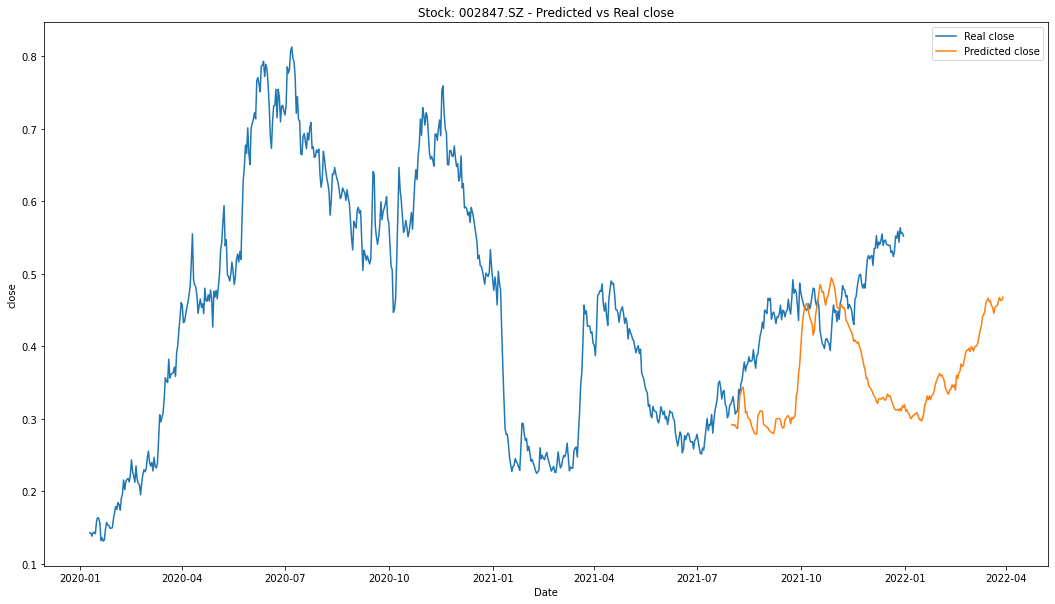

{'MSE': 0.0013031794438335147, 'RMSE': 0.036099576781916914, 'MAE': 0.030925539241108826, 'R2': 0.7954956788965475}


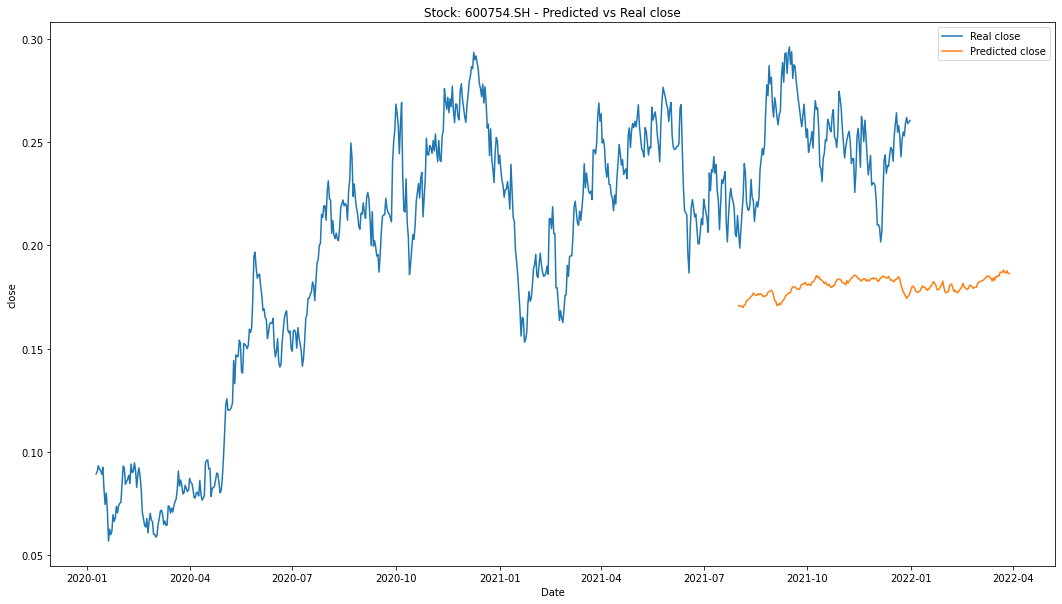

{'MSE': 0.003188297771802653, 'RMSE': 0.05646501369700226, 'MAE': 0.04983258726901264, 'R2': -2.2234613140820536}


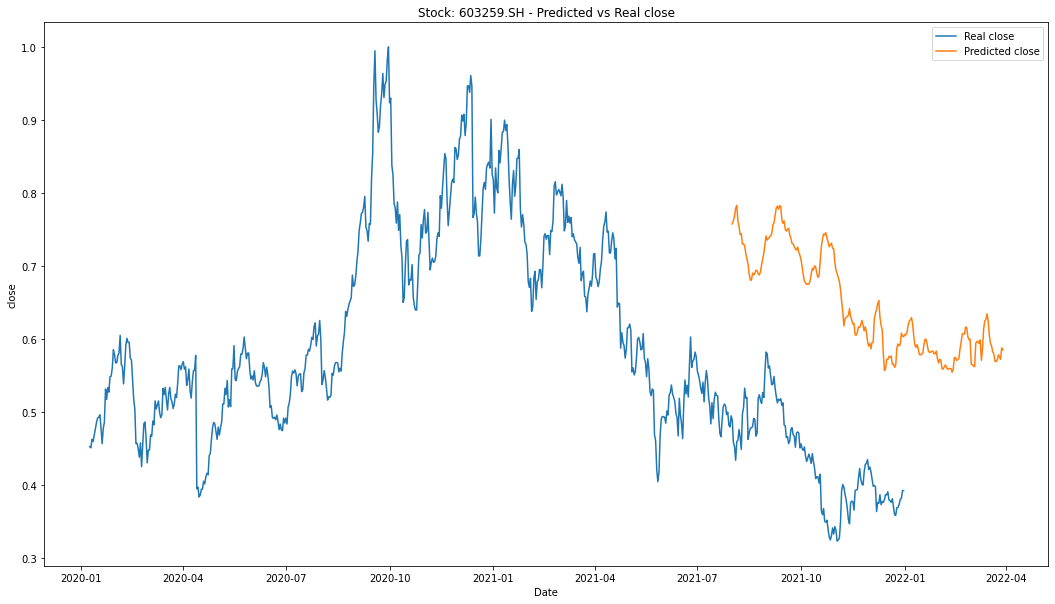

{'MSE': 0.0047704171317558275, 'RMSE': 0.06906820637424883, 'MAE': 0.05577060280071697, 'R2': 0.6090032165203713}


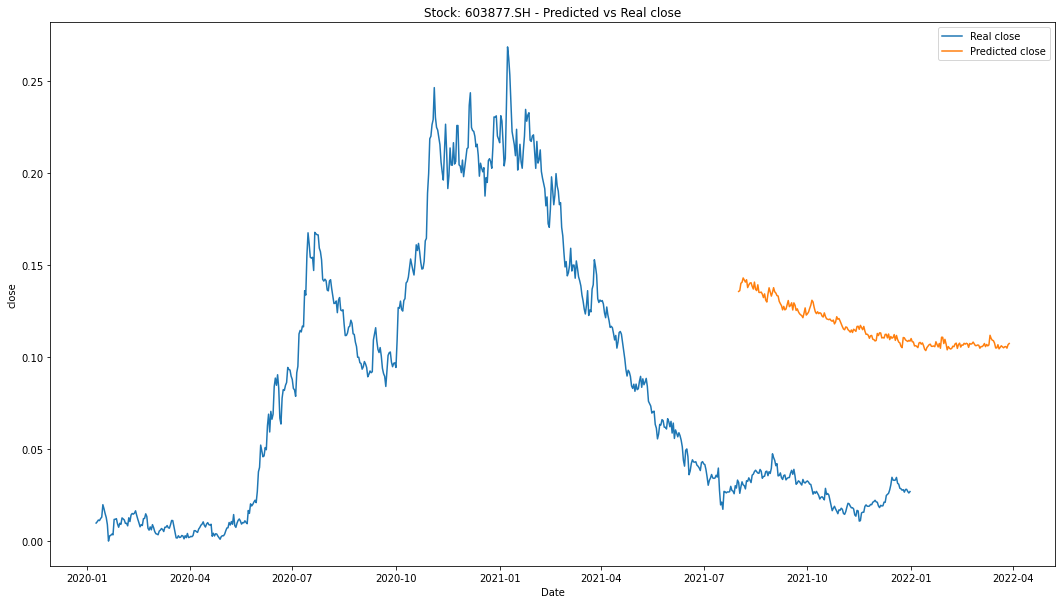

{'MSE': 0.0031699840866435576, 'RMSE': 0.05630261172133632, 'MAE': 0.05008757718673815, 'R2': 0.14099404027996987}


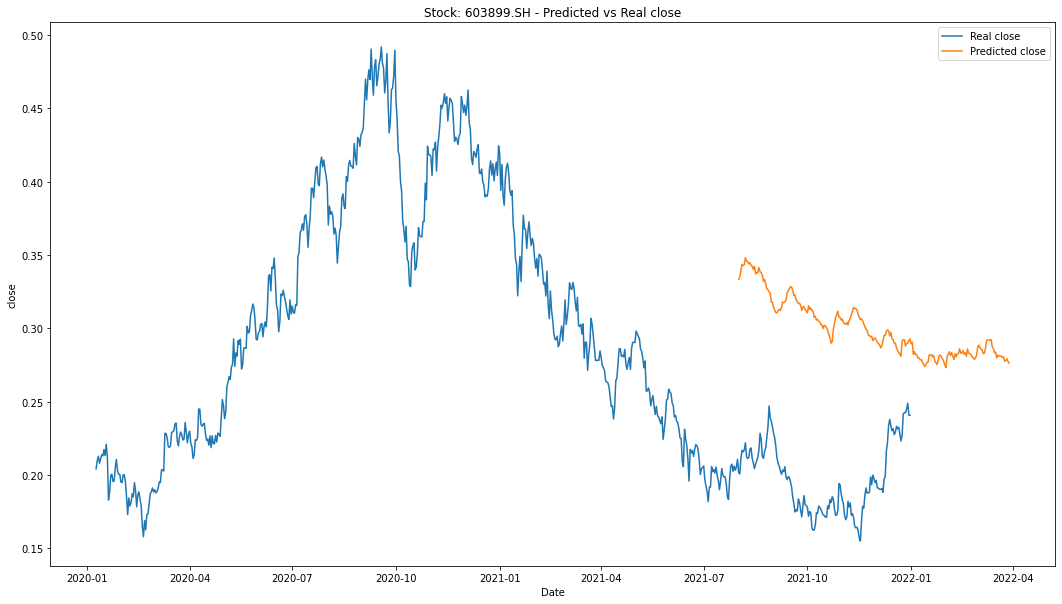

{'MSE': 0.0029053608327084895, 'RMSE': 0.05390139917208541, 'MAE': 0.046789476479433406, 'R2': -0.18372278456046343}
     ts_code       f_1       f_2       f_3       f_4       f_5       f_6  \
0  002847.SZ  0.291799  0.290690  0.291803  0.290655  0.287460  0.286417   
1  600754.SH  0.170749  0.170465  0.170735  0.170158  0.169935  0.171174   
2  603259.SH  0.757580  0.762410  0.768318  0.779199  0.782947  0.761887   
3  603877.SH  0.135780  0.136253  0.140221  0.140760  0.143119  0.142049   
4  603899.SH  0.333404  0.334809  0.339397  0.343564  0.342818  0.343229   

        f_7       f_8       f_9  ...     f_232     f_233     f_234     f_235  \
0  0.309384  0.331701  0.336929  ...  0.453522  0.445557  0.453206  0.455646   
1  0.171362  0.173166  0.173451  ...  0.185060  0.186950  0.186847  0.186994   
2  0.753936  0.743142  0.744076  ...  0.582691  0.579622  0.569665  0.569145   
3  0.140873  0.142153  0.137873  ...  0.104549  0.105371  0.106210  0.105683   
4  0.348136  0.345855  0.3

In [58]:
# SVR
results = stock_prediction(df, svr_model,start_predict_dt,forecast_n=forecast_n,target_variable=target_variable,lag_features=lag_features,drop_columns = ['ts_code', 'trade_date'], need_grid_search=need_grid_search, lagN=5,need_shap=svr_shap)
all_results['svr'] = results
write_pred(results,'svr')

### 岭回归

自回归使用到的特征变量： ['open', 'high', 'low', 'close', 'pre_close', 'change', 'pct_chg', 'vol', 'amount', 'return', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5']


The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, or maskers.Impute)


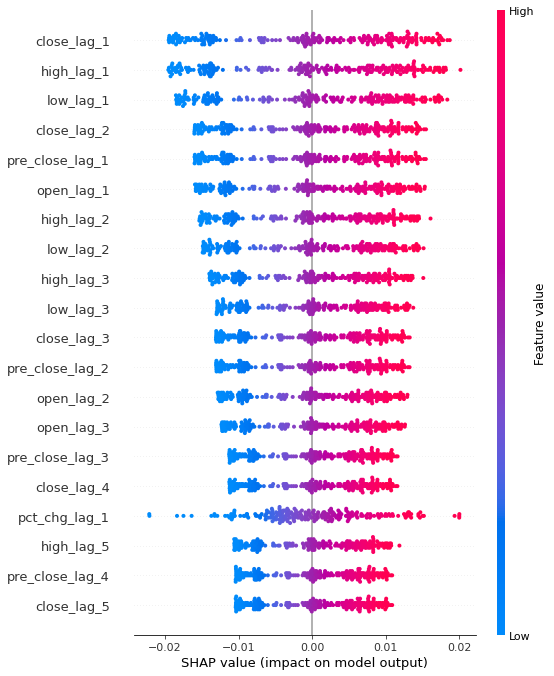

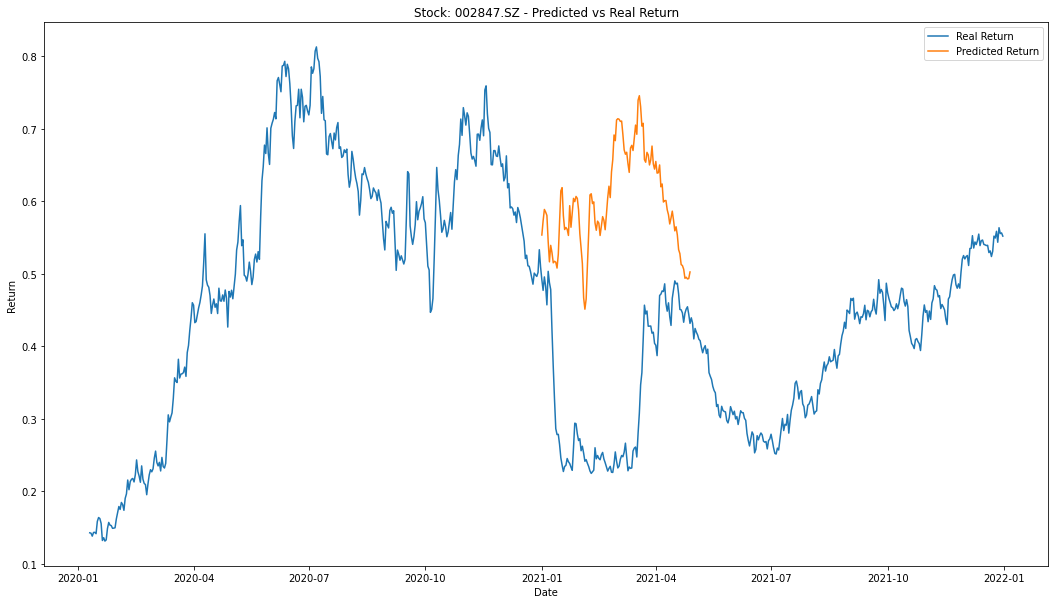

{'MSE': 0.000762232435760834, 'RMSE': 0.027608557292275054, 'MAE': 0.02066624652262548, 'R2': 0.8503845212222975}


The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, or maskers.Impute)


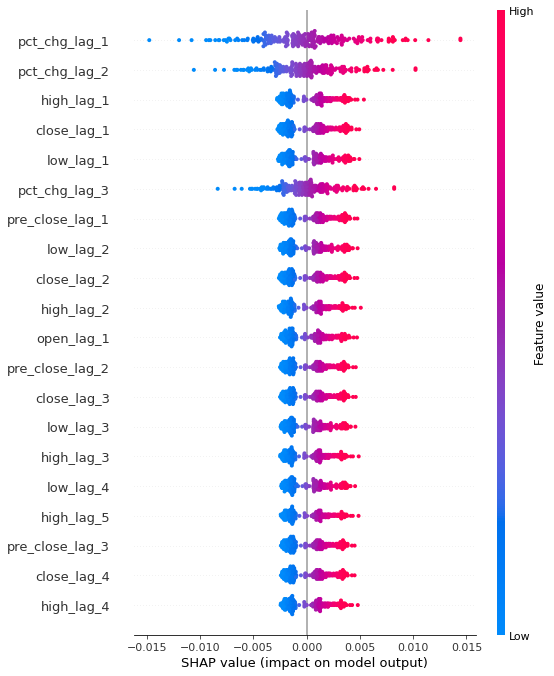

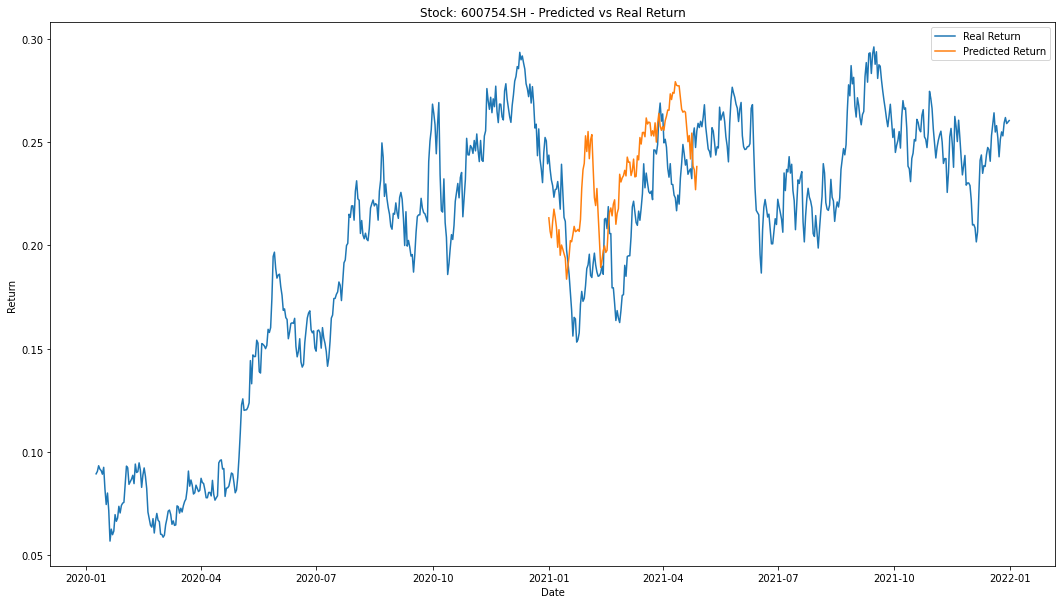

{'MSE': 0.0001902768316244423, 'RMSE': 0.013794086835468388, 'MAE': 0.01179613508054196, 'R2': 0.7553366356777099}


The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, or maskers.Impute)


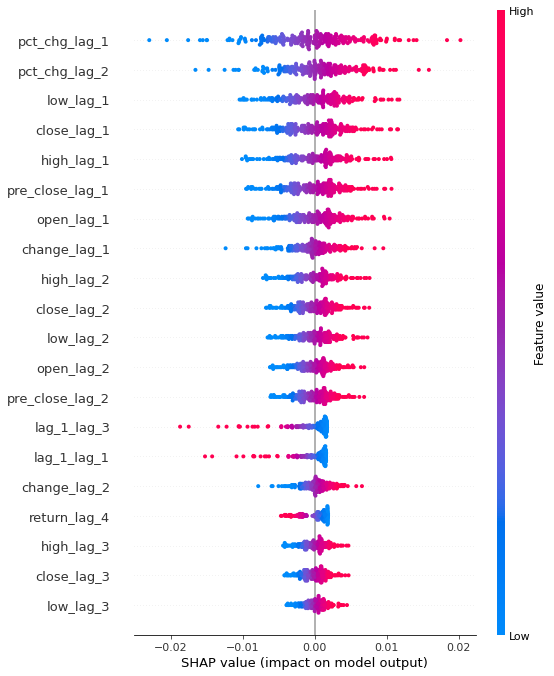

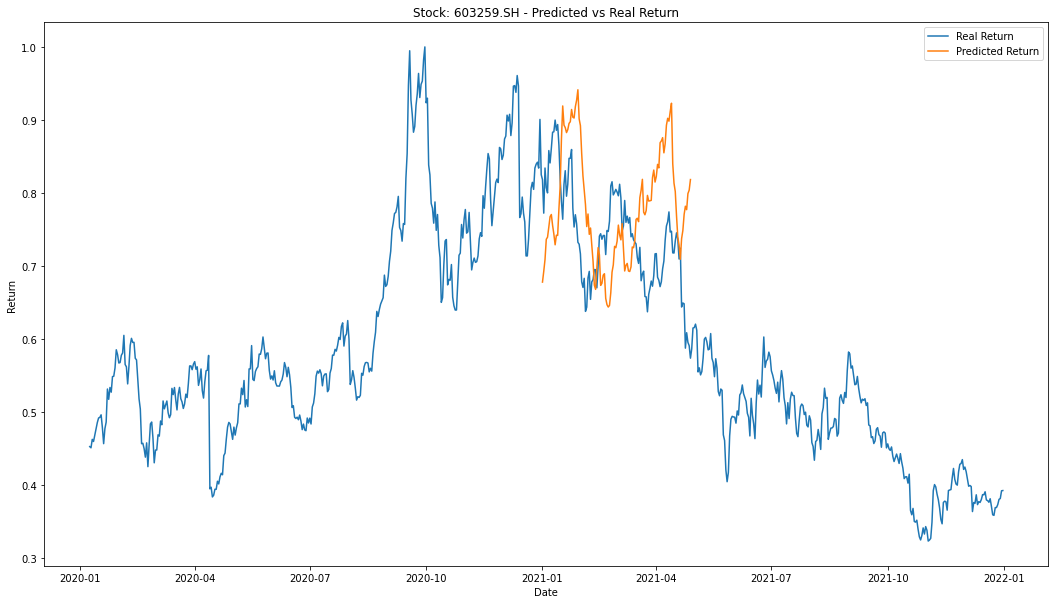

{'MSE': 0.0018632665983969517, 'RMSE': 0.04316557191092169, 'MAE': 0.03478892727944354, 'R2': 0.7617372043303372}


The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, or maskers.Impute)


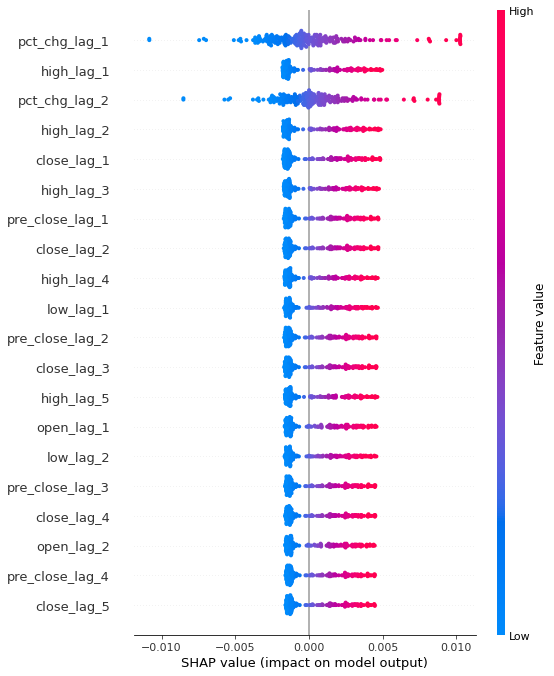

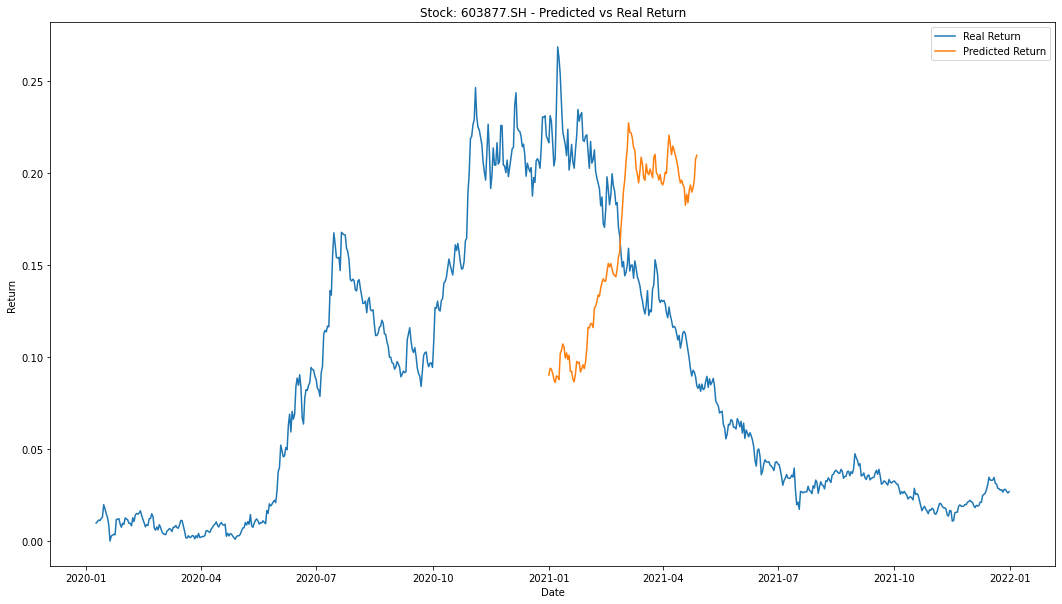

{'MSE': 0.00018937355974774488, 'RMSE': 0.013761306614843842, 'MAE': 0.010221924719955446, 'R2': 0.9249376372945869}


The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, or maskers.Impute)


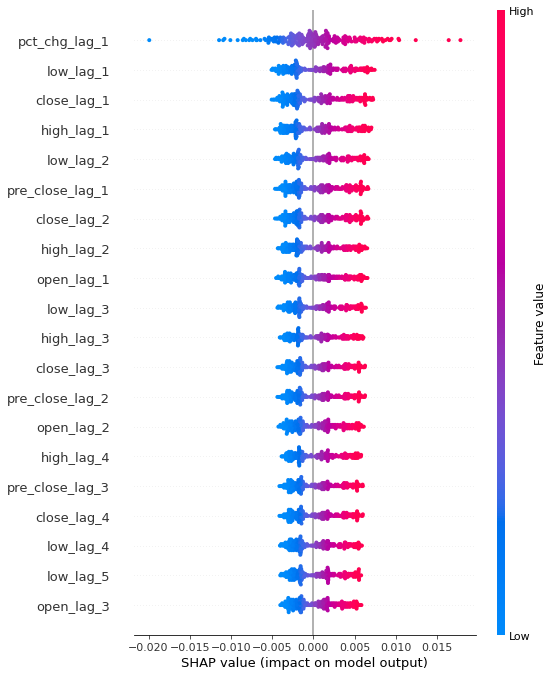

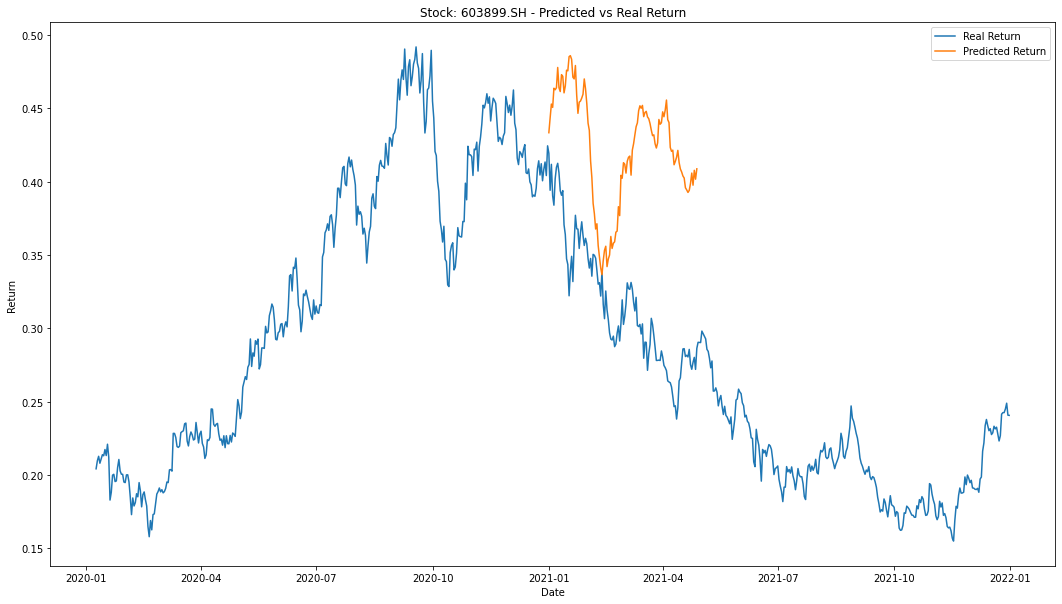

{'MSE': 0.0002197284563291172, 'RMSE': 0.014823240412579066, 'MAE': 0.01212119396119515, 'R2': 0.8648092813387691}
     ts_code       f_1       f_2       f_3       f_4       f_5       f_6  \
0  002847.SZ  0.553531  0.573030  0.588790  0.585217  0.580563  0.544566   
1  600754.SH  0.213252  0.206764  0.203644  0.211427  0.217461  0.213683   
2  603259.SH  0.677995  0.692647  0.708790  0.736585  0.739515  0.753228   
3  603877.SH  0.090323  0.094027  0.093434  0.091290  0.087970  0.086223   
4  603899.SH  0.433374  0.443353  0.452913  0.450641  0.463693  0.462656   

        f_7       f_8       f_9  ...     f_109     f_110     f_111     f_112  \
0  0.516490  0.539236  0.529282  ...  0.533400  0.527828  0.512756  0.511342   
1  0.208712  0.199013  0.207526  ...  0.264345  0.257001  0.250073  0.253055   
2  0.767576  0.770541  0.755562  ...  0.728767  0.709298  0.737463  0.748669   
3  0.089853  0.089460  0.087827  ...  0.182610  0.188663  0.184034  0.190881   
4  0.464064  0.477859  0.464

In [16]:
# 岭回归
results = stock_prediction(df, ridge_regression_model, start_predict_dt,forecast_n=forecast_n,target_variable=target_variable,drop_columns = ['ts_code', 'trade_date'], need_grid_search=need_grid_search, lagN=5,need_shap=True)
all_results['ridge_regression'] = results
write_pred(results,'ridge_regression')

### LightGBM

自回归使用到的特征变量： ['open', 'high', 'low', 'close', 'pre_close', 'change', 'pct_chg', 'vol', 'amount', 'return', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5']


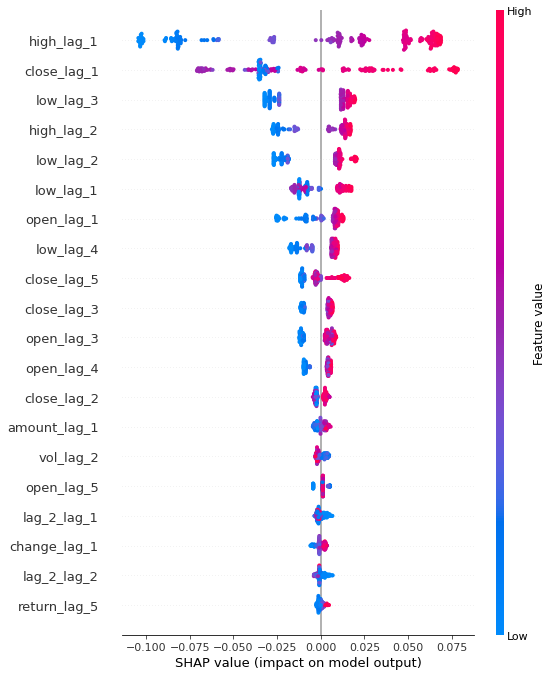

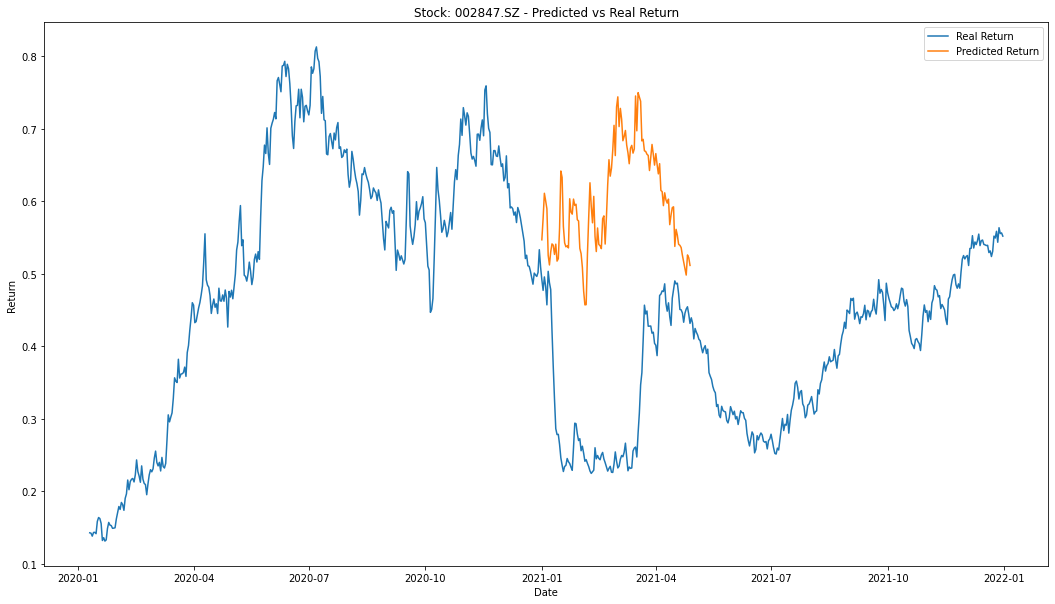

{'MSE': 0.0008785232669777277, 'RMSE': 0.02963989316744795, 'MAE': 0.02419983879380445, 'R2': 0.8275582708901327}


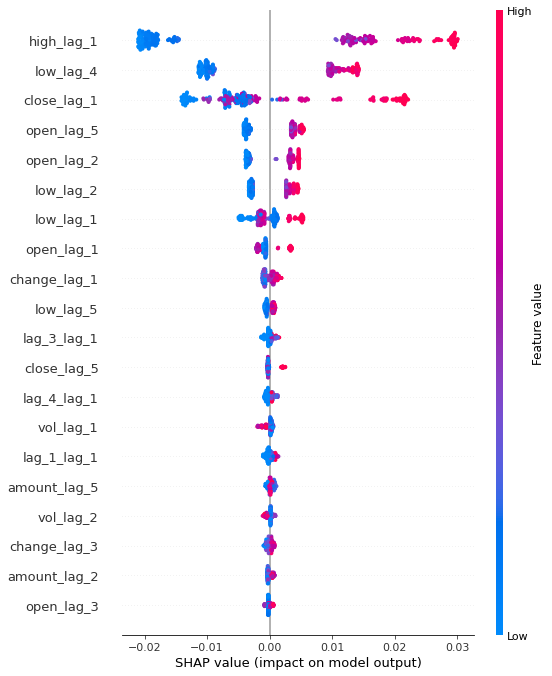

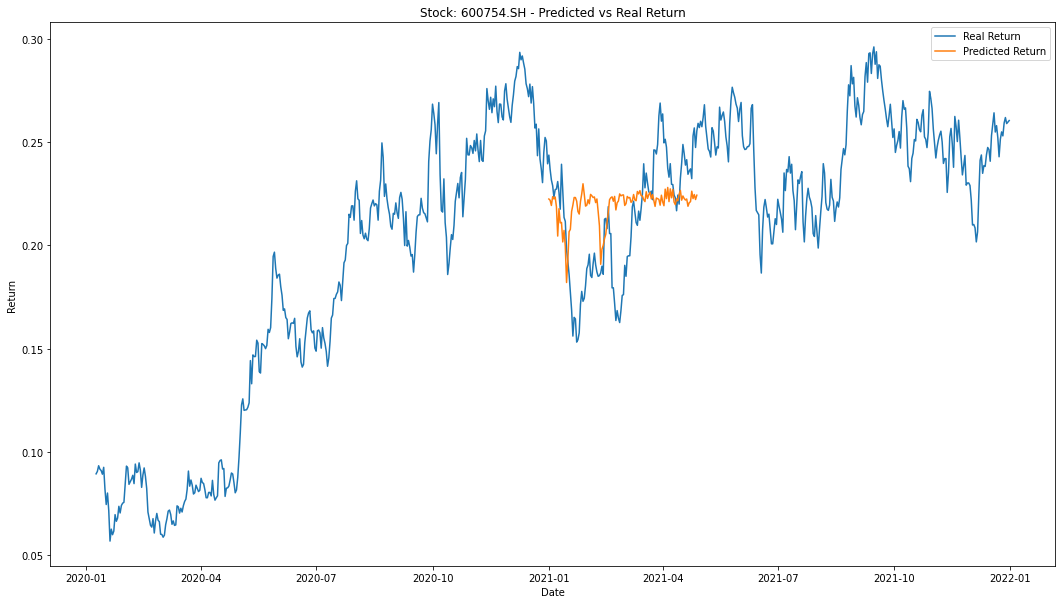

{'MSE': 0.00111292727286448, 'RMSE': 0.033360564636475805, 'MAE': 0.02714345461301154, 'R2': -0.4310335551649853}


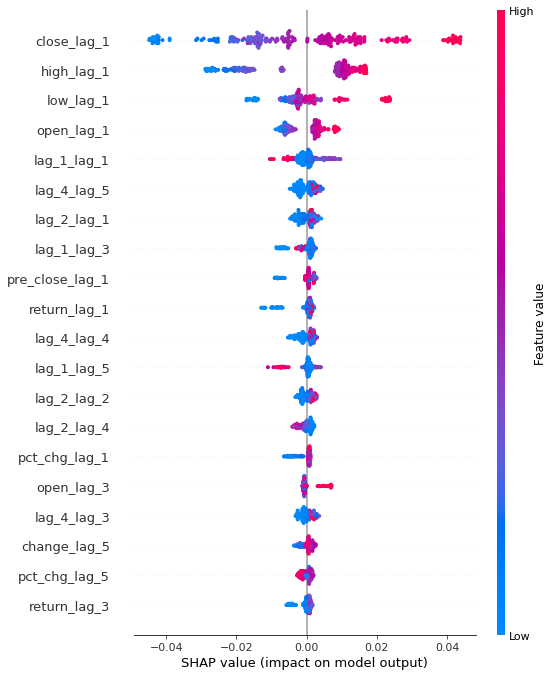

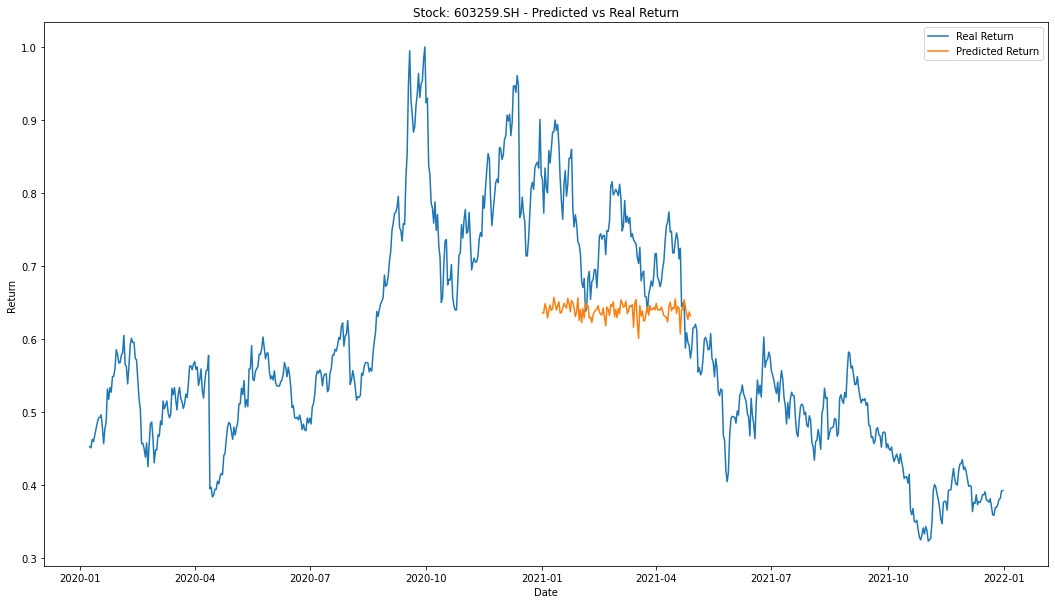

{'MSE': 0.03363699698591635, 'RMSE': 0.1834039175860656, 'MAE': 0.16089672128287774, 'R2': -3.3012872911968802}


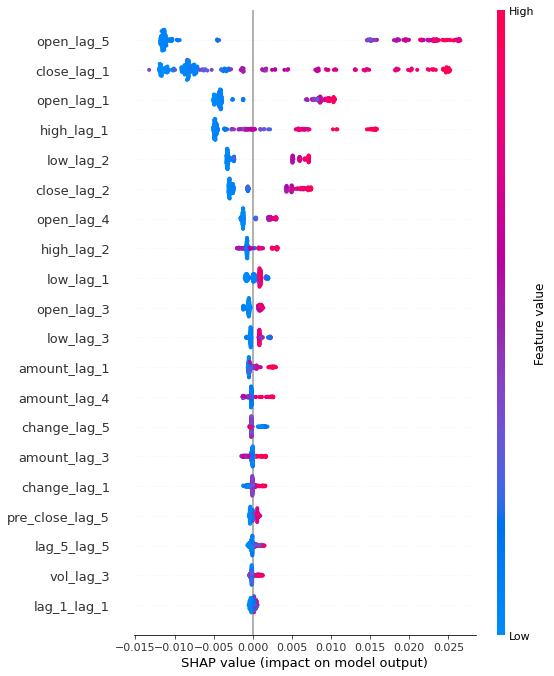

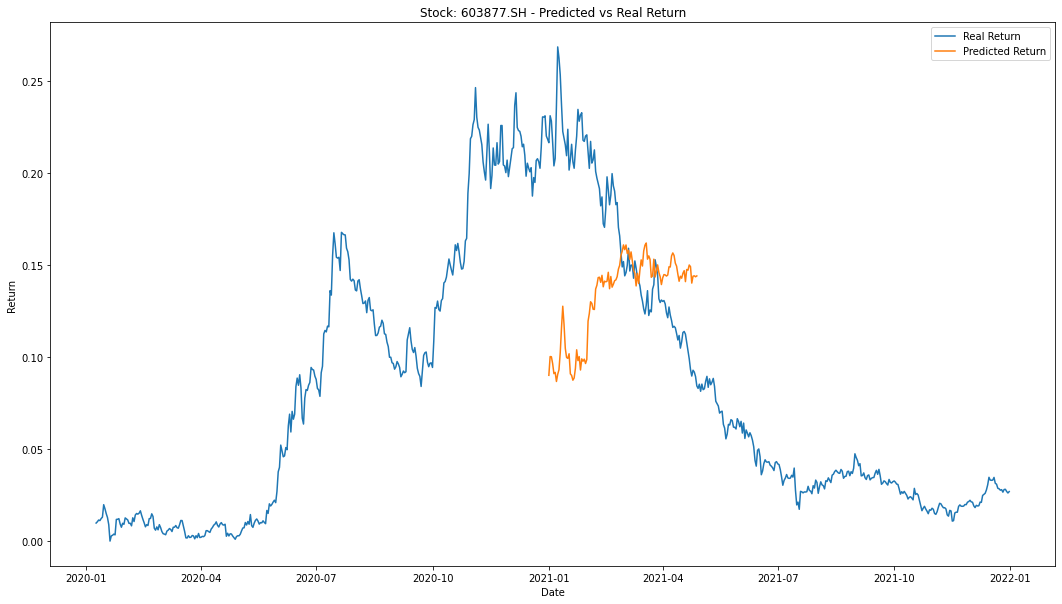

{'MSE': 0.00224324479692828, 'RMSE': 0.04736290528386408, 'MAE': 0.0367894715072891, 'R2': 0.11084073823000207}


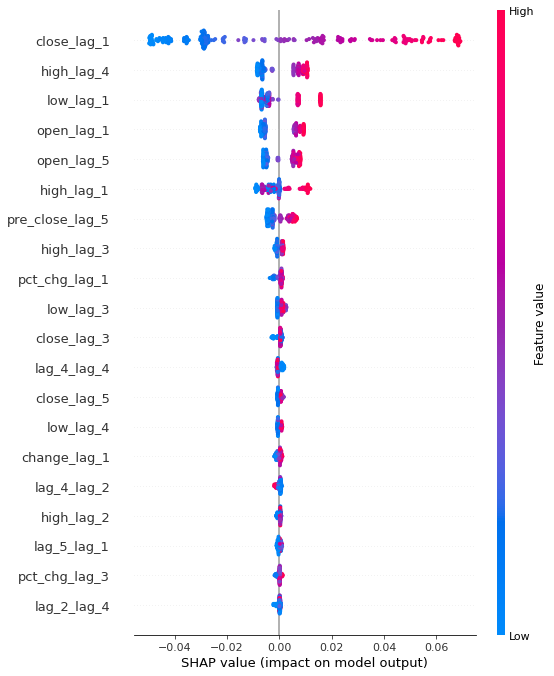

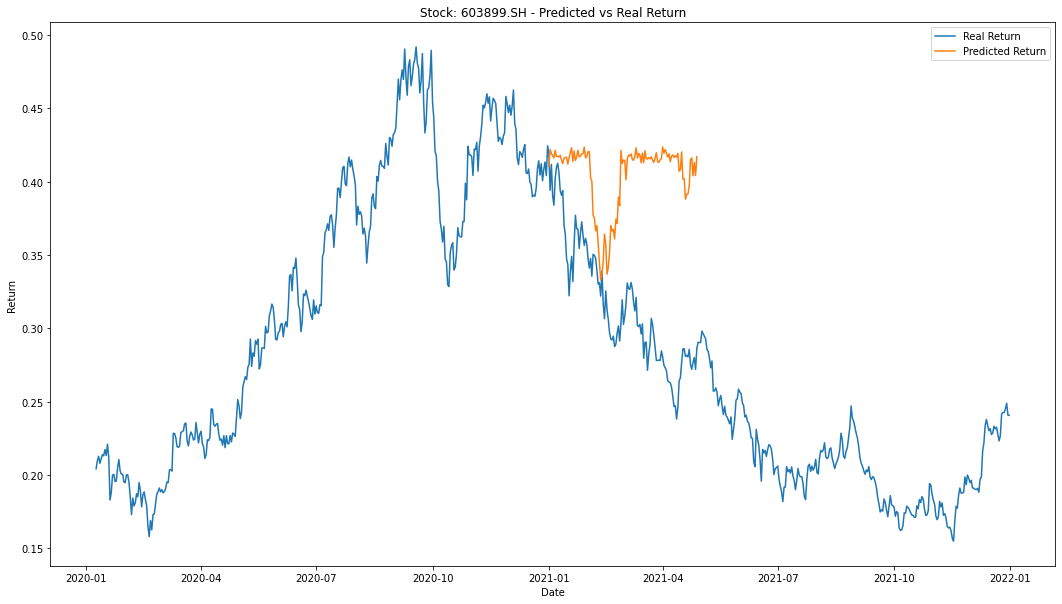

{'MSE': 0.001025679050822313, 'RMSE': 0.03202622442346761, 'MAE': 0.0245366032519622, 'R2': 0.36893795954792374}
     ts_code       f_1       f_2       f_3       f_4       f_5       f_6  \
0  002847.SZ  0.546920  0.576307  0.611132  0.600872  0.589628  0.525587   
1  600754.SH  0.222364  0.221749  0.219239  0.223495  0.222372  0.223337   
2  603259.SH  0.635644  0.636011  0.648384  0.642346  0.628932  0.639158   
3  603877.SH  0.090168  0.100368  0.100267  0.096519  0.091078  0.091752   
4  603899.SH  0.410336  0.421944  0.419118  0.417832  0.416178  0.421360   

        f_7       f_8       f_9  ...     f_109     f_110     f_111     f_112  \
0  0.512192  0.530165  0.541244  ...  0.540694  0.539318  0.536216  0.525413   
1  0.218591  0.204433  0.217663  ...  0.221864  0.222382  0.218846  0.220582   
2  0.646467  0.639212  0.641700  ...  0.641770  0.606907  0.640807  0.640053   
3  0.086810  0.090731  0.093185  ...  0.141117  0.147712  0.147332  0.150160   
4  0.417182  0.417232  0.41684

In [17]:
# LightGBM
results = stock_prediction(df, lightgbm_model, start_predict_dt,forecast_n=forecast_n,target_variable=target_variable,drop_columns = ['ts_code', 'trade_date'], need_grid_search=need_grid_search, lagN=5,need_shap=True)
all_results['lightgbm'] = results
write_pred(results,'lightgbm')

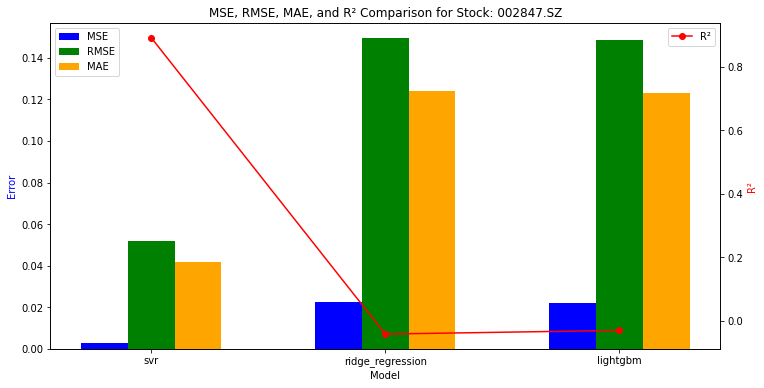

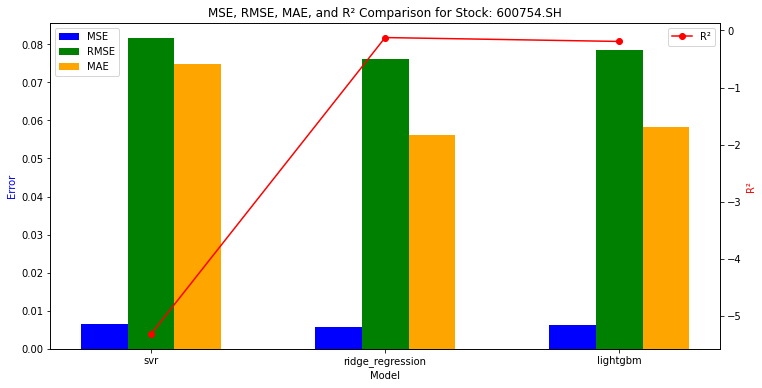

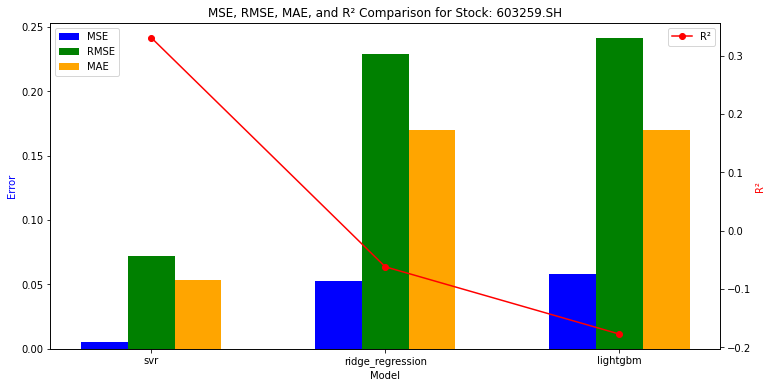

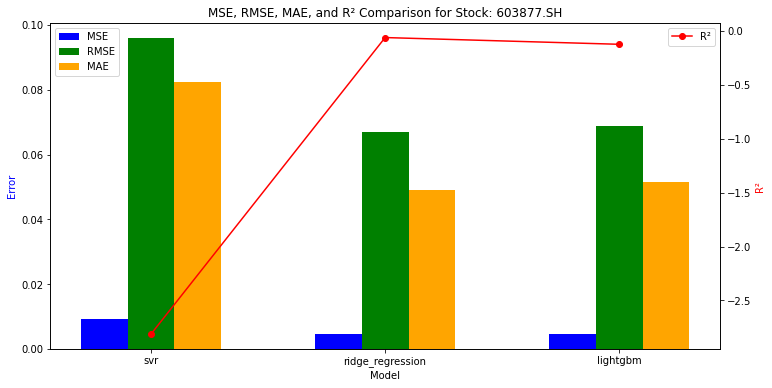

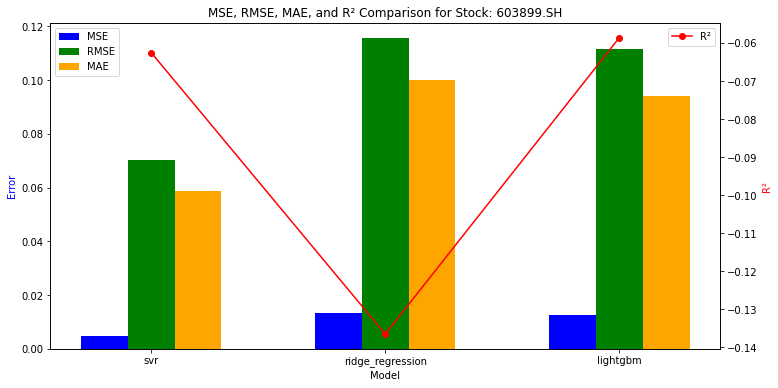

In [11]:
compare_plot(all_results)